In [1]:
library(ggplot2)
library(readxl)

In [14]:
# example 6
mu <- c(0.03, 0.05, 0.08)
sigma <- matrix(c(
0.01, 0.01, 0,
0.01, 0.04, -0.02,
0, -0.02, 0.09),
nrow = 3, ncol = 3)
min_ret <- 0.04
weights <- c(0.3, 0.5, 0.2)
ret_portfolio <- drop(weights %*% mu)
var_portfolio <- drop(t(weights) %*% sigma %*% weights)
# we can standardize the return random variable and use the cdf of the normal distribution
z_min <- (min_ret - ret_portfolio) / sqrt ( var_portfolio)
probability <- 1 - pnorm(z_min)
cat(probability)


0.5342931

In [18]:
# example 9
library(Rfast)
data <- read_excel("Return_USstock.xlsx")[c(2, 3, 4, 5, 6)]
returns <- as.matrix(data)
fitresult <- mvnorm.mle(returns)
print(fitresult)

$loglik
[1] 32742.35

$mu
[1] 0.0006605795 0.0007141874 0.0004590743 0.0010475493 0.0007272999

$sigma
               LUV          LLY        BRK-B         ADBE          DAL
LUV   3.086889e-04 5.690574e-05 8.877782e-05 1.052273e-04 2.608641e-04
LLY   5.690574e-05 1.650423e-04 5.799973e-05 6.795777e-05 7.128356e-05
BRK-B 8.877782e-05 5.799973e-05 1.223410e-04 9.047478e-05 1.013523e-04
ADBE  1.052273e-04 6.795777e-05 9.047478e-05 2.815811e-04 1.265013e-04
DAL   2.608641e-04 7.128356e-05 1.013523e-04 1.265013e-04 4.565060e-04



In [22]:
# example 10
data <- read_excel("Return_USstock.xlsx")[c(3, 4, 5)]
returns <- as.matrix(data)
dfs <- seq(from = 3, to = 5, by = 0.01)
log_likes <- numeric(length(dfs))
for (i in seq_along(dfs)){
    df <- dfs[i]
    log_likes[i] <- mvt.mle(returns, df)$loglik
}
max_index <- which.max(log_likes)
best_estimates <- mvt.mle(returns, dfs[max_index])
print(best_estimates)
print(dfs[max_index])

$iters
[1] 9

$loglik
[1] 20902.68

$location
[1] 0.0008926417 0.0004119259 0.0013620835

$scatter
             [,1]         [,2]         [,3]
[1,] 8.144703e-05 2.895473e-05 3.698861e-05
[2,] 2.895473e-05 6.173772e-05 4.649525e-05
[3,] 3.698861e-05 4.649525e-05 1.352562e-04

[1] 3.7


0.17271 0.001195335 0.006921055

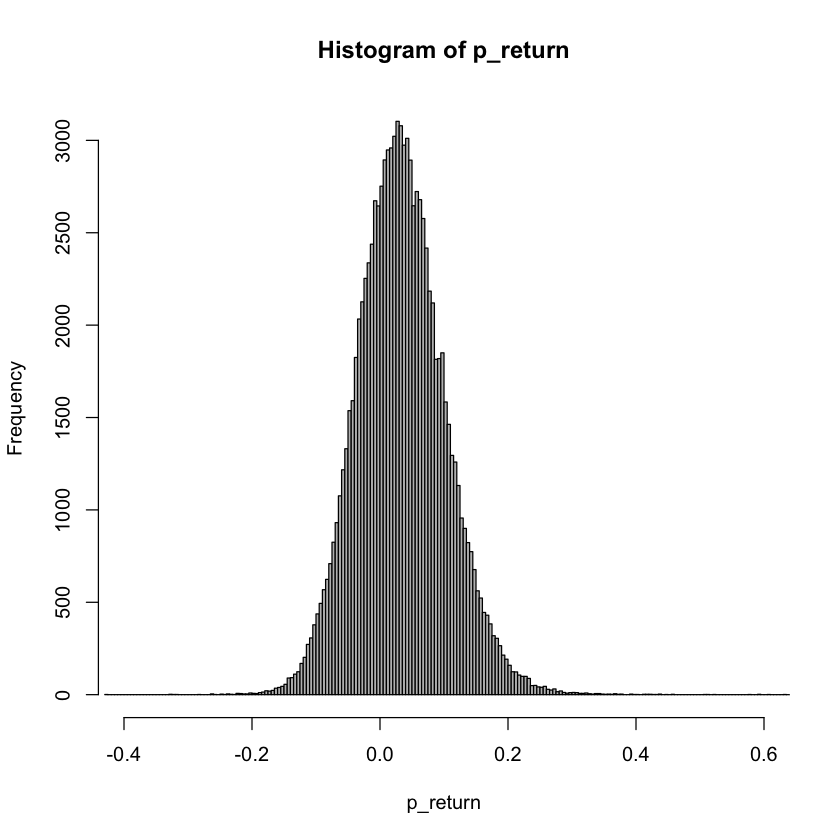

In [35]:
# example 11
set.seed(0)
weights <- c(0.2, 0.3, 0.5)
# we want to calculate the covariance matrix
n <- 100000 # number of Monte Carlo simulations
t <- 30 # we want to simulate the returns after 30 days
p_return <- numeric(n) # we store the bootstrap portfolio return
for (i in 1:n){
    w <- rep(0, 3) # placeholder for the return of each stock
    x <- rmvt(t, mu = best_estimates$location, sigma = best_estimates$scatter, v = dfs[max_index]) # we draw from the estimated distribution from the previous example
    p_return[i] <- sum(weights * exp(colSums((x)))) - 1 # total return is the sum of the returns of each stock. We use log-returns
}

# histogram of the Monte Carlo simulations
hist(p_return, breaks = 1000, xlim = c(-0.4, 0.6), col = "grey")

# we want to calculate the probabililty that the investor will lose more than 3% using this trading strategy
y <- ifelse(p_return < -0.03, no = 0, yes = 1)
estimate <- mean(y)
standard_error <- sd(y) / sqrt(n)
percentage_error <- standard_error / estimate
cat(estimate, standard_error, percentage_error) 



In [40]:
# example 12
X <- matrix(nrow = 10, ncol = 2)
X[, 1] <- 1
X[, 2] <- c(1, 2, 3, 4, 5, 6, 7, 8, 9 , 10)
Y <- c(1.4426, 3.927477, 10.858773, 7.294396, 12.101381, 15.793899, 11.518489, 20.976623, 19.937705, 17.144241)
beta_hat <- solve(t(X) %*% X, t(X) %*% Y)
beta_hat

# we can also use lm(formula y ~ x, data = X)
df <- data.frame(y = Y, x = X[, 2])
summary(lm(formula = y ~ x, data = df))

1.421545
1.941457



Call:
lm(formula = y ~ x, data = df)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.6919 -1.9135 -0.2022  2.3035  4.0234 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   1.4215     2.0733   0.686 0.512321    
x             1.9415     0.3341   5.810 0.000401 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.035 on 8 degrees of freedom
Multiple R-squared:  0.8084,	Adjusted R-squared:  0.7845 
F-statistic: 33.76 on 1 and 8 DF,  p-value: 0.0004005


In [77]:
library("quantmod")
data <- read_excel("~/Desktop/HKUST/School Work/MATH 4515/code/0005_HK.xlsx")
stock_data <- data[c("Return", "Date")]
stock_data$Date <- as.Date(stock_data$Date)
stock_data <- na.omit(stock_data)
rf <- 0.02 / 252

hsi <- getSymbols("^HSI", src = "yahoo", from = "2010-12-01", to = "2019-08-01", auto.assign = FALSE)
hsi <- na.omit(hsi)
r <- dailyReturn(Ad(hsi))

market <- data.frame(Date = as.Date(index(r)), rM = as.numeric(r))[-1, ]
capm <- merge(market, stock_data, by = "Date")
capm <- capm[capm$Date >= as.Date("2012-08-01"), ]
#a) Find the least square estimate of beta 1
X <- cbind(1, capm$rM - rf)
y <- capm$Return - rf
beta_hat <- solve(t(X) %*% X) %*% t(X) %*% y
beta_1 <- beta_hat[2]
print(beta_1)
#b) find 95% confidence interval for beta 1
n <- length(capm$Date)
p <- 1
c11 <- solve(t(X) %*% X)[2, 2]
H <- X %*% solve(t(X) %*% X) %*% t(X)
e <- (diag(n) - H) %*% y
s <- sqrt(1 / (n - p - 1) * t(e) %*% e)
v <- n - p - 1 # degrees of freedom
tL <- qt(0.025, df = v)
tU <- qt(0.975, df = v)
CI_beta1 <- data.frame("lower bound" = beta_1 - s * sqrt(c11) * tU, "Upper bound" = beta_1 - s * sqrt(c11) * tL)
print(CI_beta1)

[1] 0.7587378
  lower.bound Upper.bound
1   0.7257971   0.7916785


In [70]:
install.packages("glue")